# De-convolutional Autoencoder
###### MNIST reconstruction

Import dependencies

In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
%matplotlib inline

#### Util functions

function to plot the images after during testing phase

In [2]:
def plot_images(images, title, no_i_x, no_i_y=2):
    fig = plt.figure(figsize=(5, 15))
    fig.canvas.manager.set_window_title(title)
    images = np.array(images).reshape(-1, 28, 28)
    for i in range(no_i_x):
        for j in range(no_i_y):
            ax = fig.add_subplot(no_i_x, no_i_y, no_i_y * i + (j + 1))
            ax.matshow(images[no_i_x * j + i], cmap="gray")
            plt.xticks([])
            plt.yticks([])

            if j == 0 and i == 0:
                ax.set_title("Real")
            elif j == 1 and i == 0:
                ax.set_title("Reconstructed")

seed random number generators

In [3]:
%%capture
torch.manual_seed(42)

<br>Hyper-parameters

In [4]:
learning_rate = 0.001
batch_size = 20
images_to_plot = 10

load the mnist dataset

In [5]:
%%capture
transform = transforms.ToTensor()
train_data = datasets.MNIST(
    root='data', train=True, download=True, transform=transform)
test_data = datasets.MNIST(
    root='data', train=False, download=True, transform=transform)

split into train and validation sets (90%-10%)

In [6]:
train_set, val_set = random_split(train_data, [0.9, 0.1])

train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)

### Neural Network Model
Encoder = 2 convolutional layers + 1 fully connected layer<br>
Decoder = 2 de-convolutional layers + 1 fully connected layer<br>

#### Model

In [7]:
class DeconvAutoencoder(nn.Module):

    def __init__(self):
        super().__init__()
        # Encoder -> 2 convolutional layers (without max-pooling)
        self.encoder_conv = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=5, stride=2, padding=2),
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=5, stride=2, padding=2),
            nn.ReLU()
        )
        # Encoder -> 1 fully connected layer
        self.encoder_fc = nn.Sequential(
            nn.Linear(7 * 7 * 32, 196),
            nn.ReLU()
        )
        # Decoder -> 1 fully connected layer
        self.decoder_fc = nn.Sequential(
            nn.Linear(196, 7 * 7 * 32),
            nn.ReLU()
        )
        # Decoder -> 2 de-convolutional layers
        self.decoder_conv = nn.Sequential(
            nn.ConvTranspose2d(32, 16, kernel_size=5, stride=2, padding=2, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(16, 1, kernel_size=5, stride=2, padding=2, output_padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.encoder_conv(x)
        x = x.view(-1, 7 * 7 * 32)
        x = self.encoder_fc(x)
        x = self.decoder_fc(x)
        x = x.view(-1, 32, 7, 7)
        x = self.decoder_conv(x)
        return x


model = DeconvAutoencoder()

#### Error and Optimizer

In [8]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

#### Start Training

In [9]:
disp_imgs = []

print("*********** Train ***********")

val_iter = iter(val_loader)

for batch_idx, (data, _) in enumerate(train_loader):
    # set to trainig mode
    model.train()
    # clear gradients
    optimizer.zero_grad()
    # forward pass
    reconstructed = model(data)
    # calculate loss
    err = criterion(reconstructed, data)
    # calculate backpropogation gradient 
    err.backward()
    # update the model weights
    optimizer.step()

    if batch_idx % 100 == 0 and batch_idx != 0:
        model.eval()
        with torch.no_grad():
            try:
                val_data, _ = next(val_iter)
            except StopIteration:
                val_iter = iter(val_loader)
                val_data, _ = next(val_iter)
            val_err = criterion(model(val_data), val_data)
        print("Batch: %d validation-error = %f" % (batch_idx, val_err.item()))

*********** Train ***********
Batch: 100 validation-error = 0.067689
Batch: 200 validation-error = 0.048156
Batch: 300 validation-error = 0.027471
Batch: 400 validation-error = 0.017552
Batch: 500 validation-error = 0.014899
Batch: 600 validation-error = 0.013457
Batch: 700 validation-error = 0.012942
Batch: 800 validation-error = 0.011839
Batch: 900 validation-error = 0.011148
Batch: 1000 validation-error = 0.011193
Batch: 1100 validation-error = 0.008771
Batch: 1200 validation-error = 0.008563
Batch: 1300 validation-error = 0.009080
Batch: 1400 validation-error = 0.007920
Batch: 1500 validation-error = 0.006524
Batch: 1600 validation-error = 0.007516
Batch: 1700 validation-error = 0.006492
Batch: 1800 validation-error = 0.006883
Batch: 1900 validation-error = 0.007109
Batch: 2000 validation-error = 0.006098
Batch: 2100 validation-error = 0.005381
Batch: 2200 validation-error = 0.006337
Batch: 2300 validation-error = 0.006810
Batch: 2400 validation-error = 0.005807
Batch: 2500 validat

#### Testing

In [10]:
print("*********** Test ***********")

model.eval()
test_batch, _ = next(iter(test_loader))
with torch.no_grad():
    reconstructed_imgs = model(test_batch)
    test_err = criterion(reconstructed_imgs, test_batch)

print("Test Error: %.8f" % test_err.item())

for i in range(images_to_plot):
    disp_imgs.append(test_batch[i].cpu().numpy().reshape(-1, 28, 28))
for i in range(images_to_plot):
    disp_imgs.append(reconstructed_imgs[i].cpu().numpy().reshape(-1, 28, 28))

*********** Test ***********
Test Error: 0.00453590


#### plot output

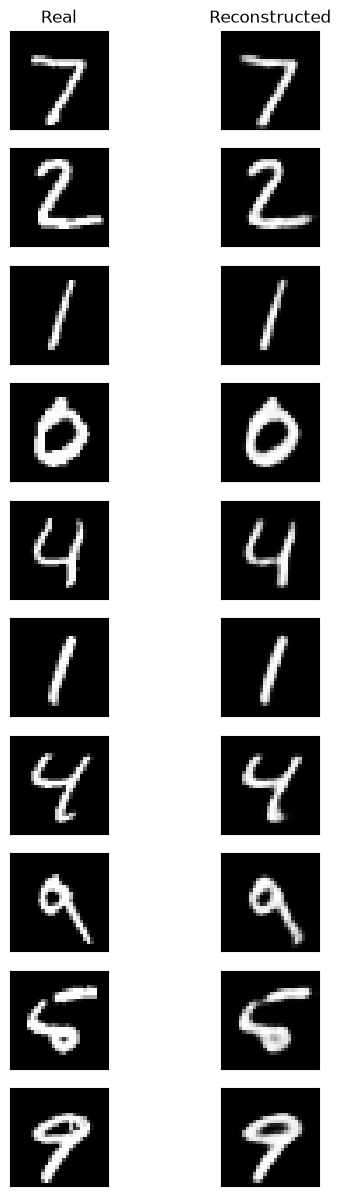

In [11]:
plot_images(disp_imgs, "Auto-encoder", images_to_plot)
plt.show()